# Statistical Analysis of Student Mathematics Performance

## Research focus
**Do extra paid mathematics classes improve students' final mathematics grades?**

This notebook presents the statistical analysis for the research project *Learning Comparison: Extra Paid Classes and Mathematics Grades*. The analysis examines whether participation in extra paid mathematics classes is associated with students' final mathematics performance.

The final mathematics grade (`G3`) is the primary outcome variable, while participation in extra paid mathematics classes (`paid`) is the principal explanatory variable. Earlier grades and selected student-background and learning-support variables are also examined.

The analysis uses descriptive statistics, graphical exploration, confidence intervals, hypothesis testing, correlation and multiple linear regression. A sensitivity analysis is included to examine how the treatment of zero final grades affects the findings.

**Study design:** Quantitative analysis of secondary, observational student-performance data. The results identify associations and do not establish causal effects.

## 1. Data Sources and Import

The analysis uses the mathematics component of the Student Performance dataset associated with two Portuguese secondary schools. The original data contain 395 student records and 33 recorded variables. A student identifier was added to support record matching, resulting in 34 columns in the supplied CSV files.

Three supporting files are provided for this project:

- **Raw CSV:** the original 395 student records, including records with a final grade (`G3`) of zero.
- **Cleaned CSV:** the 357 records retained for the primary analysis after excluding the 38 records with `G3 = 0`.
- **Excel workbook:** a supporting workbook containing the raw and cleaned data, preprocessing notes, descriptive summaries, inferential analyses, regression output and charts.

These files represent different versions or presentations of the same underlying student dataset; they are not three independent samples. The records are therefore not combined or counted more than once.

The following cell imports the project files into the notebook environment.

In [1]:
from google.colab import files
uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving student_mat_clean.csv to student_mat_clean.csv
Saving student_mat_raw_with_id.csv to student_mat_raw_with_id.csv
Saving Student_Performance_Analysis.xlsx to Student_Performance_Analysis.xlsx
Uploaded files: ['student_mat_clean.csv', 'student_mat_raw_with_id.csv', 'Student_Performance_Analysis.xlsx']


## 2. Statistical Software and Data Loading

Python was used to conduct the statistical analysis. The principal libraries are pandas and NumPy for data handling, Matplotlib and Seaborn for visualisation, SciPy for statistical tests, and statsmodels for regression modelling and diagnostics.

The raw and cleaned CSV files are loaded separately so that the cleaning procedure can be reproduced and checked. The Excel workbook is retained as a supporting project reference.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

raw_file = next(f for f in uploaded if f.lower().endswith("student_mat_raw_with_id.csv"))
clean_file = next(f for f in uploaded if f.lower().endswith("student_mat_clean.csv"))
xlsx_file = next((f for f in uploaded if f.lower().endswith("student_performance_analysis.xlsx")), None)

raw = pd.read_csv(raw_file)
supplied_clean = pd.read_csv(clean_file)

print("Raw data shape:", raw.shape)
print("Supplied clean data shape:", supplied_clean.shape)

if xlsx_file:
    xls = pd.ExcelFile(xlsx_file)
    print("Excel workbook sheets:", xls.sheet_names)

Raw data shape: (395, 34)
Supplied clean data shape: (357, 34)
Excel workbook sheets: ['README', 'Raw_Data', 'Clean_Data', 'Preprocessing', 'Descriptives', 'CI_ttest', 'Raw_by_group', 'Chi_square', 'Correlation', 'Regression', 'Charts']


## 3. Initial Data Inspection

The raw dataset is examined to establish its dimensions, variable structure, missing-value status, duplicate records and the distribution of final mathematics grades. This inspection provides the basis for deciding whether further data preparation is required.

In [3]:
display(raw.head())
raw.info()
print("\\nMissing values per column:")
display(raw.isna().sum().to_frame("missing_count").query("missing_count > 0"))
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate student IDs:", raw["student_id"].duplicated().sum())
print("Unique paid values:", raw["paid"].value_counts(dropna=False))
print("G3 values summary:")
display(raw["G3"].describe())

,student_id,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,S001,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,S002,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,S003,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,S004,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,S005,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   student_id  395 non-null    object
 1   school      395 non-null    object
 2   sex         395 non-null    object
 3   age         395 non-null    int64 
 4   address     395 non-null    object
 5   famsize     395 non-null    object
 6   Pstatus     395 non-null    object
 7   Medu        395 non-null    int64 
 8   Fedu        395 non-null    int64 
 9   Mjob        395 non-null    object
 10  Fjob        395 non-null    object
 11  reason      395 non-null    object
 12  guardian    395 non-null    object
 13  traveltime  395 non-null    int64 
 14  studytime   395 non-null    int64 
 15  failures    395 non-null    int64 
 16  schoolsup   395 non-null    object
 17  famsup      395 non-null    object
 18  paid        395 non-null    object
 19  activities  395 non-null    object
 20  nursery   

,missing_count


Duplicate rows: 0
Duplicate student IDs: 0
Unique paid values: paid
no     214
yes    181
Name: count, dtype: int64
G3 values summary:


,G3
count,395.000
mean,10.415
std,4.581
min,0.000
25%,8.000
50%,11.000
75%,14.000
max,20.000


## 4. Data Cleaning and Verification

The supplied cleaned dataset contains 357 records. The difference from the 395 original records is 38 observations with a final grade of zero (`G3 = 0`).

The research paper treats these zero final grades as potentially unrecorded final assessments rather than observed achievement scores. This decision is examined using the available information, including earlier grades and recorded absences. The cleaned sample is reconstructed from the raw data and compared with the supplied cleaned CSV to verify record consistency.

Because the dataset does not explicitly explain the meaning of these zero grades, the exclusion is treated as an analytical decision that requires qualification. The main analysis uses the 357-record sample, while a separate sensitivity analysis retains all 395 records.

In [4]:
zero_rows = raw.loc[raw["G3"].eq(0)].copy()
print("Raw students:", len(raw))
print("Records with G3 = 0:", len(zero_rows))
print("Records with G3 > 0:", raw["G3"].gt(0).sum())
print("Among G3 = 0 records, absences value counts:")
display(zero_rows["absences"].value_counts(dropna=False).to_frame("students"))
print("Mean G1 among G3 = 0 records:", zero_rows["G1"].mean())
print("Number with G2 = 0 among G3 = 0 records:", zero_rows["G2"].eq(0).sum())
print("\\nPaid-class status among G3 = 0 records:")
display(zero_rows["paid"].value_counts())

clean = raw.loc[raw["G3"].gt(0)].copy()

print("\\nRecreated clean shape:", clean.shape)
print("Supplied clean shape:", supplied_clean.shape)
print("Student IDs match:", set(clean["student_id"]) == set(supplied_clean["student_id"]))

# Check all original columns and values after sorting by student ID
raw_filtered = clean[ supplied_clean.columns ].sort_values("student_id").reset_index(drop=True)
given_clean = supplied_clean.sort_values("student_id").reset_index(drop=True)
print("Clean CSV exactly matches raw data filtered to G3 > 0:",
      raw_filtered.equals(given_clean))

Raw students: 395
Records with G3 = 0: 38
Records with G3 > 0: 357
Among G3 = 0 records, absences value counts:


,students
absences,
0,38


Mean G1 among G3 = 0 records: 7.526315789473684
Number with G2 = 0 among G3 = 0 records: 13
\nPaid-class status among G3 = 0 records:


,count
paid,
no,30
yes,8


\nRecreated clean shape: (357, 34)
Supplied clean shape: (357, 34)
Student IDs match: True
Clean CSV exactly matches raw data filtered to G3 > 0: True


## 5. Variable Preparation and Operational Definitions

The principal variables are defined as follows:

- **Final mathematics grade (`G3`):** the dependent/outcome variable, measured on a 0–20 scale.
- **Extra paid mathematics classes (`paid`):** the main explanatory variable, recorded as yes or no.
- **First- and second-period grades (`G1`, `G2`):** earlier measures of mathematics performance.
- **Pass status:** a derived binary variable coded as 1 when `G3` is at least 10 and 0 otherwise.
- **Additional explanatory variables:** study time, past failures, absences, mother's education, school support, family support, sex and school.

The pass threshold of 10 follows the grading definition used in the project. Categorical yes/no variables are standardised for analysis, and the derived pass indicator is created from the final grade.

In [5]:
for frame in [raw, clean]:
    frame["paid"] = frame["paid"].astype(str).str.strip().str.lower()
    frame["paid_yes"] = frame["paid"].map({"yes": 1, "no": 0})
    frame["pass"] = np.where(frame["G3"] >= 10, 1, 0)

print("Clean analysis sample:", len(clean))
print(clean[["G1", "G2", "G3", "paid", "paid_yes", "pass"]].head())

Clean analysis sample: 357
   G1  G2  G3 paid  paid_yes  pass
0   5   6   6   no         0     0
1   5   5   6   no         0     0
2   7   8  10  yes         1     1
3  15  14  15  yes         1     1
4   6  10  10  yes         1     1


## 6. Descriptive Statistical Analysis

Descriptive statistics summarise the central tendency, variability and range of the academic and selected background variables. The analysis reports the sample size, mean, standard deviation, minimum, quartiles, median and maximum.

Final-grade summaries are also calculated separately for students who attended extra paid mathematics classes and those who did not. These summaries provide an initial description of the two groups before formal hypothesis testing.

In [6]:
numeric_cols = ["G1", "G2", "G3", "studytime", "failures", "absences", "Medu", "age"]
desc = clean[numeric_cols].describe().T
desc["median"] = clean[numeric_cols].median()
desc = desc[["count", "mean", "std", "min", "25%", "median", "75%", "max"]]
display(desc)

group_desc = clean.groupby("paid")["G3"].agg(
    n="count", mean="mean", std="std", median="median", minimum="min", maximum="max"
)
display(group_desc)

,count,mean,std,min,25%,median,75%,max
G1,357.000,11.269,3.240,3.000,9.000,11.000,14.000,19.000
G2,357.000,11.359,3.147,5.000,9.000,11.000,14.000,19.000
G3,357.000,11.524,3.228,4.000,9.000,11.000,14.000,20.000
studytime,357.000,2.042,0.832,1.000,1.000,2.000,2.000,4.000
failures,357.000,0.272,0.672,0.000,0.000,0.000,0.000,3.000
absences,357.000,6.317,8.188,0.000,2.000,4.000,8.000,75.000
Medu,357.000,2.796,1.094,0.000,2.000,3.000,4.000,4.000
age,357.000,16.655,1.268,15.000,16.000,17.000,18.000,22.000


,n,mean,std,median,minimum,maximum
paid,,,,,,
no,184,11.614,3.402,11.000,5,20
yes,173,11.428,3.039,11.000,4,19


## 7. Exploratory Data Analysis and Visualisation

Graphical analysis is used to examine the distribution of final grades and compare the two paid-class groups. Histograms show the distribution of `G3` before and after the cleaning decision. A box plot with individual observations compares final-grade distributions across paid-class groups. A correlation heatmap summarises relationships among selected numerical variables.

These visualisations support the interpretation of the data and help identify patterns; they are not, by themselves, evidence of a causal relationship.

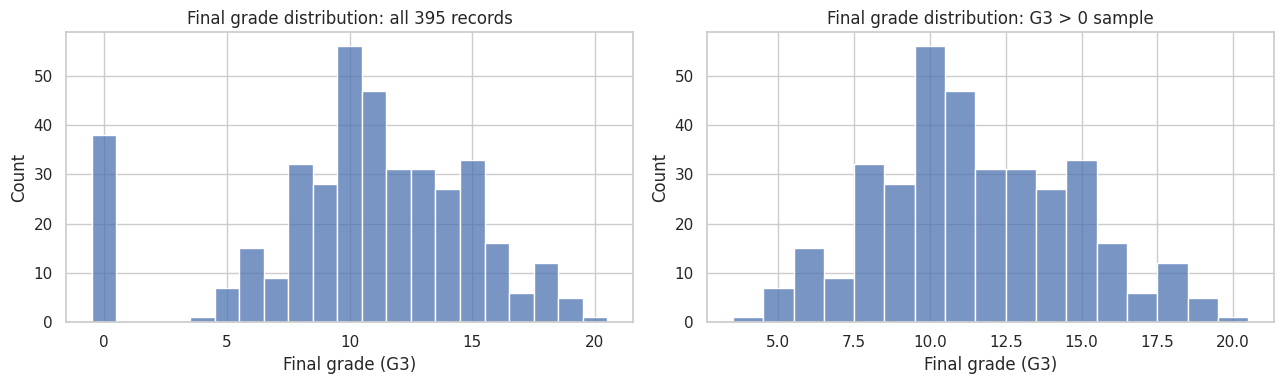

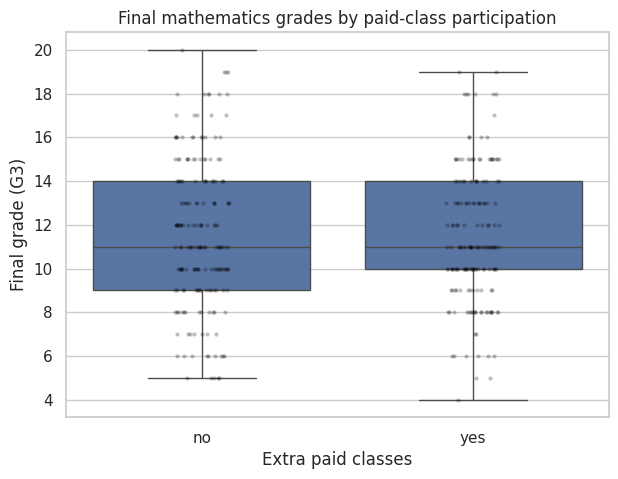

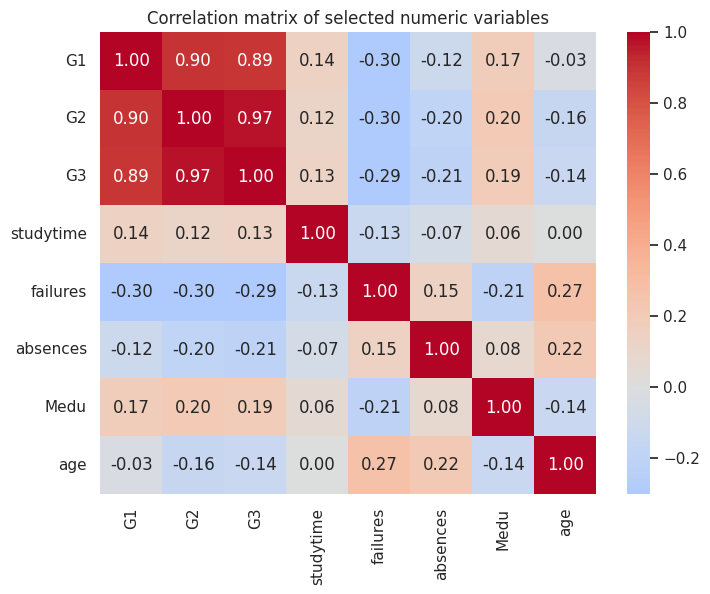

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(raw["G3"], bins=np.arange(-0.5, 21.5, 1), ax=axes[0])
axes[0].set_title("Final grade distribution: all 395 records")
axes[0].set_xlabel("Final grade (G3)")
sns.histplot(clean["G3"], bins=np.arange(3.5, 21.5, 1), ax=axes[1])
axes[1].set_title("Final grade distribution: G3 > 0 sample")
axes[1].set_xlabel("Final grade (G3)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(data=clean, x="paid", y="G3")
sns.stripplot(data=clean, x="paid", y="G3", color="black", alpha=.25, size=3)
plt.title("Final mathematics grades by paid-class participation")
plt.xlabel("Extra paid classes")
plt.ylabel("Final grade (G3)")
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(clean[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix of selected numeric variables")
plt.show()

## 8. Comparison of Mean Final Grades: Welch's Independent-Samples t-Test

The primary inferential comparison examines whether the mean final mathematics grade differs between students who attended extra paid classes and students who did not.

**Hypotheses**

- **Null hypothesis (H₀):** The population mean final grade is equal for the two paid-class groups.
- **Alternative hypothesis (H₁):** The population mean final grade differs between the two paid-class groups.

Welch's independent-samples t-test is applied because it does not require the two groups to have equal population variances. The analysis reports the group means and standard deviations, the mean difference (paid minus not paid), the test statistic, p-value, 95% confidence interval and Cohen's *d* effect size. The significance level is 0.05.

In [8]:
yes = clean.loc[clean["paid"] == "yes", "G3"].dropna()
no = clean.loc[clean["paid"] == "no", "G3"].dropna()

test = stats.ttest_ind(yes, no, equal_var=False)
n1, n0 = len(yes), len(no)
m1, m0 = yes.mean(), no.mean()
v1, v0 = yes.var(ddof=1), no.var(ddof=1)
difference = m1 - m0
se_diff = np.sqrt(v1/n1 + v0/n0)
welch_df = (v1/n1 + v0/n0)**2 / ((v1/n1)**2/(n1-1) + (v0/n0)**2/(n0-1))
t_critical = stats.t.ppf(0.975, welch_df)
ci_low = difference - t_critical * se_diff
ci_high = difference + t_critical * se_diff
pooled_sd = np.sqrt(((n1-1)*v1 + (n0-1)*v0)/(n1+n0-2))
cohens_d = difference / pooled_sd

print(f"Paid group: n={n1}, mean={m1:.3f}, SD={yes.std(ddof=1):.3f}")
print(f"No-paid group: n={n0}, mean={m0:.3f}, SD={no.std(ddof=1):.3f}")
print(f"Mean difference (paid - no paid) = {difference:.3f}")
print(f"Welch t({welch_df:.1f}) = {test.statistic:.3f}, p = {test.pvalue:.4f}")
print(f"95% CI for difference = [{ci_low:.3f}, {ci_high:.3f}]")
print(f"Cohen's d = {cohens_d:.3f}")

Paid group: n=173, mean=11.428, SD=3.039
No-paid group: n=184, mean=11.614, SD=3.402
Mean difference (paid - no paid) = -0.186
Welch t(354.1) = -0.547, p = 0.5850
95% CI for difference = [-0.857, 0.484]
Cohen's d = -0.058


### Decision Rule and Interpretation

At the 5% significance level, a p-value below 0.05 provides evidence against the null hypothesis. A p-value of 0.05 or greater indicates that the analysis does not provide sufficient evidence of a difference in population means.

The confidence interval and effect size are interpreted alongside the p-value. A result that is not statistically significant should not be described as proof that the groups are identical or that paid classes have no effect.

## 9. Non-Parametric Robustness Analysis: Mann–Whitney U Test

The Mann–Whitney U test provides a rank-based comparison of the final-grade distributions for the two paid-class groups. It is included as a supplementary robustness check to assess whether the broad conclusion is consistent with a non-parametric method.

The test is interpreted as a comparison of the groups' rank distributions; it is not automatically interpreted as a test of equality of medians in every circumstance.

In [9]:
mw = stats.mannwhitneyu(yes, no, alternative="two-sided")
print(f"Mann–Whitney U = {mw.statistic:.1f}, p = {mw.pvalue:.4f}")

Mann–Whitney U = 15418.5, p = 0.6082


## 10. Association Between Paid Classes and Pass Status: Chi-Square Test

Pass status is defined as a final grade of 10 or above. A chi-square test of independence is used to examine whether pass/fail status is associated with participation in extra paid mathematics classes.

- **Null hypothesis (H₀):** Pass/fail status is independent of paid-class participation.
- **Alternative hypothesis (H₁):** Pass/fail status is associated with paid-class participation.

The observed contingency table, expected frequencies, chi-square statistic, degrees of freedom and p-value are reported. Cramér's V is calculated to describe the strength of association.

In [10]:
table = pd.crosstab(clean["paid"], clean["pass"])
table.columns = ["Fail (<10)", "Pass (>=10)"]
display(table)

chi2, p_chi, dof, expected = stats.chi2_contingency(table, correction=False)
n_total = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / n_total)
pass_rates = clean.groupby("paid")["pass"].mean()

print(f"Chi-square({dof}) = {chi2:.3f}, p = {p_chi:.4f}")
print("Pass rates:")
display(pass_rates.rename("pass_rate").to_frame())
print(f"Cramer's V = {cramers_v:.3f}")
print("Expected frequencies:")
display(pd.DataFrame(expected, index=table.index, columns=table.columns))

,Fail (<10),Pass (>=10)
paid,,
no,49,135
yes,43,130


Chi-square(1) = 0.147, p = 0.7016
Pass rates:


,pass_rate
paid,
no,0.734
yes,0.751


Cramer's V = 0.020
Expected frequencies:


,Fail (<10),Pass (>=10)
paid,,
no,47.417,136.583
yes,44.583,128.417


## 11. Examination of Zero Final Grades

The 38 records with `G3 = 0` are examined separately to assess whether the occurrence of zero final grades differs between students who did and did not attend paid classes.

This analysis is relevant to the data-cleaning decision because an unequal rate of zero final grades across the two groups could influence the uncleaned comparison. The chi-square test evaluates the association between paid-class status and the presence of a zero final grade. It does not establish why a zero was recorded or whether paid classes affected course completion.

In [11]:
raw["G3_zero"] = (raw["G3"] == 0).astype(int)
zero_table = pd.crosstab(raw["paid"], raw["G3_zero"])
zero_table.columns = ["G3 above zero", "G3 equals zero"]
display(zero_table)
chi2_zero, p_zero, dof_zero, expected_zero = stats.chi2_contingency(zero_table, correction=False)
print(f"Chi-square({dof_zero}) = {chi2_zero:.3f}, p = {p_zero:.4f}")
print("Zero-grade proportion by paid status:")
display(raw.groupby("paid")["G3_zero"].mean().rename("proportion_G3_zero").to_frame())

,G3 above zero,G3 equals zero
paid,,
no,184,30
yes,173,8


Chi-square(1) = 10.391, p = 0.0013
Zero-grade proportion by paid status:


,proportion_G3_zero
paid,
no,0.140
yes,0.044


## 12. Correlation Analysis

Correlation analysis examines the direction and strength of relationships between final mathematics grade (`G3`) and selected numerical variables, including earlier grades, study time, past failures, absences, mother's education and age.

Pearson's correlation coefficient measures linear association. Spearman's rank correlation is also calculated as a supplementary measure of monotonic association. Correlation does not establish causation, and strong relationships between earlier grades and the final grade are interpreted as associations within this dataset.

In [12]:
correlation_vars = ["G1", "G2", "G3", "studytime", "failures", "absences", "Medu", "age"]
pearson = clean[correlation_vars].corr(method="pearson")
spearman = clean[correlation_vars].corr(method="spearman")
print("Pearson correlation matrix:")
display(pearson)
print("Spearman correlation matrix:")
display(spearman)

for variable in ["G1", "G2", "studytime", "failures", "absences", "Medu", "age"]:
    r, p = stats.pearsonr(clean[variable], clean["G3"])
    print(f"{variable:12s}: r={r:.3f}, p={p:.4g}")

Pearson correlation matrix:


,G1,G2,G3,studytime,failures,absences,Medu,age
G1,1.000,0.902,0.892,0.141,-0.302,-0.120,0.172,-0.031
G2,0.902,1.000,0.966,0.120,-0.301,-0.200,0.203,-0.158
G3,0.892,0.966,1.000,0.127,-0.294,-0.213,0.190,-0.140
studytime,0.141,0.120,0.127,1.000,-0.131,-0.075,0.056,0.000
failures,-0.302,-0.301,-0.294,-0.131,1.000,0.148,-0.215,0.272
absences,-0.120,-0.200,-0.213,-0.075,0.148,1.000,0.076,0.216
Medu,0.172,0.203,0.190,0.056,-0.215,0.076,1.000,-0.140
age,-0.031,-0.158,-0.140,0.000,0.272,0.216,-0.140,1.000


Spearman correlation matrix:


,G1,G2,G3,studytime,failures,absences,Medu,age
G1,1.000,0.897,0.887,0.137,-0.279,-0.160,0.175,-0.015
G2,0.897,1.000,0.962,0.112,-0.299,-0.255,0.208,-0.159
G3,0.887,0.962,1.000,0.110,-0.299,-0.244,0.192,-0.148
studytime,0.137,0.112,0.110,1.000,-0.117,-0.072,0.054,0.037
failures,-0.279,-0.299,-0.299,-0.117,1.000,0.256,-0.202,0.235
absences,-0.160,-0.255,-0.244,-0.072,0.256,1.000,0.055,0.226
Medu,0.175,0.208,0.192,0.054,-0.202,0.055,1.000,-0.133
age,-0.015,-0.159,-0.148,0.037,0.235,0.226,-0.133,1.000


G1          : r=0.892, p=2.473e-124
G2          : r=0.966, p=1.034e-209
studytime   : r=0.127, p=0.01659
failures    : r=-0.294, p=1.534e-08
absences    : r=-0.213, p=4.917e-05
Medu        : r=0.190, p=0.0002989
age         : r=-0.140, p=0.007905


## 13. Multiple Linear Regression: Adjusted Analysis

Multiple linear regression is used to examine the association between paid-class participation and final mathematics grade while accounting for other observed student characteristics.

The dependent variable is `G3`. Paid-class participation is the principal explanatory variable. The model also includes first-period grade, past failures, study time, absences, mother's education, school support, family support, sex and school. Including prior achievement is particularly important because students may differ in their starting performance before the final assessment.

HC3 heteroskedasticity-robust standard errors are used for inference. The paid-class coefficient, robust p-value and 95% confidence interval are examined alongside the model's R-squared and adjusted R-squared. As the data are observational, the adjusted coefficient is interpreted as an association rather than a causal effect.

In [13]:
formula = ("G3 ~ C(paid) + G1 + failures + studytime + absences + Medu "
           "+ C(schoolsup) + C(famsup) + C(sex) + C(school)")
model = smf.ols(formula, data=clean).fit(cov_type="HC3")
print(model.summary())

paid_terms = [term for term in model.params.index if "C(paid)" in term]
for term in paid_terms:
    print("\\nAdjusted paid-class estimate:")
    print("Coefficient:", model.params[term])
    print("Robust p-value:", model.pvalues[term])
    print("95% CI:", model.conf_int().loc[term].tolist())
print("R-squared:", model.rsquared)
print("Adjusted R-squared:", model.rsquared_adj)

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.815
Model:                            OLS   Adj. R-squared:                  0.809
Method:                 Least Squares   F-statistic:                     167.4
Date:                Wed, 11 Nov 2026   Prob (F-statistic):          5.05e-126
Time:                        09:10:44   Log-Likelihood:                -623.40
No. Observations:                 357   AIC:                             1269.
Df Residuals:                     346   BIC:                             1311.
Df Model:                          10                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               2.0098    

### Interpretation of the Regression Model

The coefficient for paid-class participation estimates the adjusted difference in final grade between the paid-class and no-paid-class groups, conditional on the other variables included in the model.

The coefficient's direction, magnitude, robust p-value and confidence interval should be considered together. The model's explanatory power does not imply that the included variables cause changes in final grades.

## 14. Regression Diagnostics

Regression diagnostics are examined to assess whether the fitted model presents notable issues. The residuals-versus-fitted plot is used to inspect patterns in residual spread and model fit. A Q–Q plot is used to assess how closely the residual distribution follows a normal distribution.

The Breusch–Pagan test examines evidence of heteroskedasticity. Variance inflation factors (VIFs) are calculated to assess potential multicollinearity among explanatory variables. These diagnostics inform the limitations and interpretation of the regression model; they do not by themselves prove that every model assumption is satisfied.

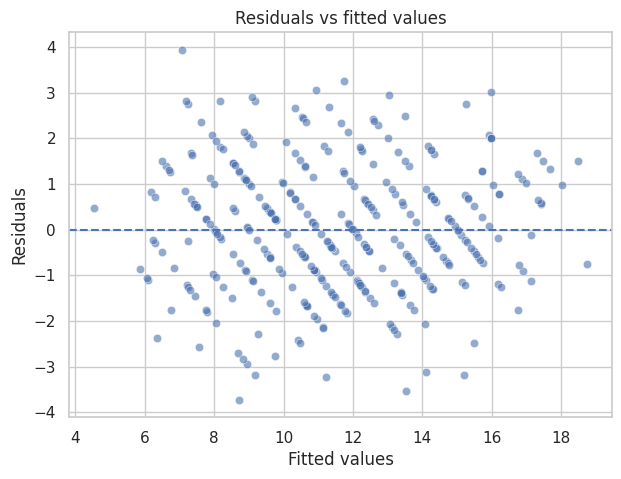

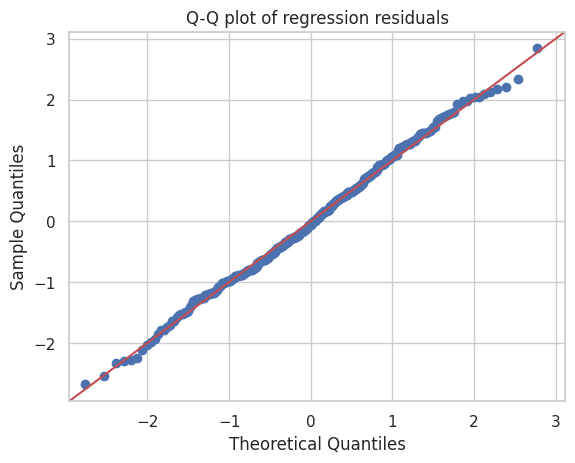

Breusch-Pagan LM statistic: 17.770854678330554
Breusch-Pagan p-value: 0.05895422624884603


,variable,VIF
6,G1,1.265
3,C(famsup)[T.yes],1.192
7,failures,1.184
8,studytime,1.183
4,C(sex)[T.M],1.178
1,C(paid)[T.yes],1.151
2,C(schoolsup)[T.yes],1.145
10,Medu,1.140
5,C(school)[T.MS],1.082
9,absences,1.078


In [14]:
fitted = model.fittedvalues
resid = model.resid

plt.figure(figsize=(7, 5))
sns.scatterplot(x=fitted, y=resid, alpha=.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs fitted values")
plt.show()

sm.qqplot(resid, line="45", fit=True)
plt.title("Q-Q plot of regression residuals")
plt.show()

bp = het_breuschpagan(resid, model.model.exog)
print("Breusch-Pagan LM statistic:", bp[0])
print("Breusch-Pagan p-value:", bp[1])

# VIF for the model's design matrix (excluding intercept)
X = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
vif_table = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
display(vif_table.query("variable != 'Intercept'").sort_values("VIF", ascending=False))

## 15. Sensitivity Analysis: Including All 395 Records

The primary analysis excludes the 38 observations with `G3 = 0` because the research paper treats these values as potentially unrecorded final grades. To assess how consequential this decision is, the Welch t-test is repeated using all 395 original records.

The results from the full sample and the cleaned sample are compared. Any change in the direction, magnitude or statistical significance of the group difference is discussed as evidence that the conclusion is sensitive to the treatment of zero final grades. The dataset does not explicitly confirm the reason for each zero, so both the analytical decision and its limitation are reported transparently.

In [15]:
raw_yes = raw.loc[raw["paid"] == "yes", "G3"]
raw_no = raw.loc[raw["paid"] == "no", "G3"]
raw_test = stats.ttest_ind(raw_yes, raw_no, equal_var=False)

print("ALL 395 records, zeros included")
print(f"Paid mean = {raw_yes.mean():.3f} (n={len(raw_yes)})")
print(f"No-paid mean = {raw_no.mean():.3f} (n={len(raw_no)})")
print(f"Difference = {raw_yes.mean()-raw_no.mean():.3f}")
print(f"Welch t = {raw_test.statistic:.3f}, p = {raw_test.pvalue:.4f}")

print("\\n357 records, G3 > 0")
print(f"Paid mean = {yes.mean():.3f} (n={len(yes)})")
print(f"No-paid mean = {no.mean():.3f} (n={len(no)})")
print(f"Difference = {yes.mean()-no.mean():.3f}")
print(f"Welch t = {test.statistic:.3f}, p = {test.pvalue:.4f}")

ALL 395 records, zeros included
Paid mean = 10.923 (n=181)
No-paid mean = 9.986 (n=214)
Difference = 0.937
Welch t = 2.083, p = 0.0379
\n357 records, G3 > 0
Paid mean = 11.428 (n=173)
No-paid mean = 11.614 (n=184)
Difference = -0.186
Welch t = -0.547, p = 0.5850


## 16. Supplementary Regression Model Including the Second-Period Grade

A supplementary regression model adds `G2` to the explanatory variables. This model is compared with the primary regression model to examine how the estimated paid-class association changes when the second-period grade is also controlled.

Because `G2` is measured during the same academic year and is strongly related to the final grade, this model is treated as supplementary rather than as the principal adjusted analysis. Its coefficient estimates are interpreted with this timing and relationship in mind.

In [16]:
model_with_g2 = smf.ols(
    "G3 ~ C(paid) + G1 + G2 + failures + studytime + absences + Medu + C(schoolsup) + C(famsup) + C(sex) + C(school)",
    data=clean
).fit(cov_type="HC3")
print(model_with_g2.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.937
Model:                            OLS   Adj. R-squared:                  0.935
Method:                 Least Squares   F-statistic:                     531.1
Date:                Wed, 11 Nov 2026   Prob (F-statistic):          1.02e-208
Time:                        09:11:05   Log-Likelihood:                -432.07
No. Observations:                 357   AIC:                             888.1
Df Residuals:                     345   BIC:                             934.7
Df Model:                          11                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.4496    

## 17. Summary of Statistical Findings

The following table brings together the principal group-comparison and association tests. It provides a concise overview for interpretation and for reporting the findings in the research paper.

The table should be read alongside the descriptive summaries, confidence interval, effect size and regression output. Statistical significance is not treated as a substitute for considering the size and practical meaning of the observed differences.

In [17]:
results = pd.DataFrame([
    {"Analysis": "Welch t-test, G3 > 0 sample", "Statistic": test.statistic, "p_value": test.pvalue,
     "Main result": f"Mean difference (paid - no paid) = {difference:.3f}; 95% CI [{ci_low:.3f}, {ci_high:.3f}]"},
    {"Analysis": "Mann–Whitney U, G3 > 0 sample", "Statistic": mw.statistic, "p_value": mw.pvalue,
     "Main result": "Rank-based robustness check"},
    {"Analysis": "Chi-square, pass/fail", "Statistic": chi2, "p_value": p_chi,
     "Main result": f"Pass rates: paid={pass_rates.get('yes', np.nan):.1%}; no paid={pass_rates.get('no', np.nan):.1%}"},
    {"Analysis": "Welch t-test, all 395 incl. zeros", "Statistic": raw_test.statistic, "p_value": raw_test.pvalue,
     "Main result": f"Mean difference (paid - no paid) = {raw_yes.mean()-raw_no.mean():.3f}"},
])
display(results)

,Analysis,Statistic,p_value,Main result
0,"Welch t-test, G3 > 0 sample",-0.547,0.585,Mean difference (paid - no paid) = -0.186; 95%...
1,"Mann–Whitney U, G3 > 0 sample","15,418.500",0.608,Rank-based robustness check
2,"Chi-square, pass/fail",0.147,0.702,Pass rates: paid=75.1%; no paid=73.4%
3,"Welch t-test, all 395 incl. zeros",2.083,0.038,Mean difference (paid - no paid) = 0.937


## 18. Overall Interpretation, Conclusion and Limitations

The final interpretation brings together the descriptive findings, group comparisons, pass-rate analysis, correlations, regression results and sensitivity analysis. The conclusion should answer the research question directly while distinguishing statistical association from causation.

The following limitations are considered when interpreting the findings:

- The data are observational; students were not randomly assigned to paid classes, so causal conclusions cannot be established.
- Paid-class participation is recorded as yes/no and does not describe the duration, quality or format of tutoring.
- The sample consists of students from two Portuguese secondary schools in the 2005–2006 academic year, which limits generalisation to other populations and periods.
- The meaning of the 38 zero final grades is inferred from the observed data and is not explicitly documented in the dataset.
- Statistical significance, effect size and practical importance are distinct considerations.

The conclusion should be based on the computed outputs in this notebook rather than on expected or previously reported values.

## 19. Exporting Statistical Output Tables

Selected descriptive statistics, group summaries, correlation matrices and test results are exported as CSV files. These tables can be used as supporting material when preparing the written research report and presentation.

In [18]:
desc.to_csv("descriptive_statistics.csv")
group_desc.to_csv("grade_summary_by_paid_class.csv")
pearson.to_csv("pearson_correlation_matrix.csv")
spearman.to_csv("spearman_correlation_matrix.csv")
results.to_csv("statistical_test_summary.csv", index=False)

print("Saved: descriptive_statistics.csv")
print("Saved: grade_summary_by_paid_class.csv")
print("Saved: pearson_correlation_matrix.csv")
print("Saved: spearman_correlation_matrix.csv")
print("Saved: statistical_test_summary.csv")

Saved: descriptive_statistics.csv
Saved: grade_summary_by_paid_class.csv
Saved: pearson_correlation_matrix.csv
Saved: spearman_correlation_matrix.csv
Saved: statistical_test_summary.csv
